[Sommaire](00_sommaire.ipynb) · ⬅ [Thème 5 — BFS / DFS](theme5_bfs_dfs.ipynb) · [Thème 7 — Maths et gloutons](theme7_maths_gloutons.ipynb) ➡

# Thème 6 — Sommes préfixes, recherche dichotomique et tri

**Dans ce notebook, tu vas apprendre :**
- précalculer des **sommes préfixes** pour répondre en O(1) à « quelle est la somme entre la position `g` et la position `d` ? » ;
- chercher dans une liste triée en coupant la zone de recherche en deux à chaque étape : la **recherche dichotomique**, en O(log n) ;
- trier avec une **clé** (`key=`), et pourquoi trier d'abord simplifie beaucoup de problèmes.

**Prérequis :** thèmes 0, 1 et 3 (notation O, set et dict, portion contiguë)

> Exécute d'abord la cellule ci-dessous : elle contient l'outil `verifier`, qui teste automatiquement ta solution dans l'exercice final.

In [ ]:
# Outil utilisé dans l'exercice « À toi de jouer » de ce notebook.
# Il appelle ta fonction sur plusieurs cas et affiche ✅ (bon), ❌ (mauvais) ou 💥 (plantage).
# Tu n'as pas besoin de comprendre ce code pour t'en servir : exécute simplement cette cellule.

import copy

def verifier(fonction, cas):
    reussis = 0
    for arguments, attendu in cas:
        texte_args = ", ".join(repr(a) for a in arguments)
        try:
            obtenu = fonction(*copy.deepcopy(arguments))
        except Exception as erreur:
            print(f"💥 {fonction.__name__}({texte_args}) a planté : {type(erreur).__name__}: {erreur}")
            continue
        if obtenu == attendu:
            reussis += 1
            print(f"✅ {fonction.__name__}({texte_args}) -> {obtenu!r}")
        else:
            print(f"❌ {fonction.__name__}({texte_args}) -> {obtenu!r}   (attendu : {attendu!r})")
    print(f"\n{reussis}/{len(cas)} tests réussis")

## Partie 1 — Les sommes préfixes

### Le problème de départ
> Un magasin note ses ventes de chaque jour : `ventes = [3, 1, 4, 1, 5, 9, 2, 6]` (le premier jour est le jour 0). Le gérant pose **beaucoup** de questions du type : « combien a-t-on vendu du jour `g` au jour `d`, inclus ? »
> Du jour 2 au jour 5 → 4 + 1 + 5 + 9 = **19**.

**Approche naïve** : pour chaque question, additionner les jours concernés avec `sum(ventes[g:d + 1])`. Mais `sum` est une boucle cachée (thème 0) : O(n) par question. Avec 100 000 jours et 100 000 questions, cela fait jusqu'à 10 milliards d'additions.

Remarque : d'une question à l'autre, on refait sans cesse les mêmes additions.

### Le concept : le compteur kilométrique
Le compteur d'une voiture affiche le nombre de kilomètres parcourus **depuis le départ**. Pour savoir combien de kilomètres séparent Lyon de Marseille, on ne refait pas le trajet : on lit le compteur à Marseille et on soustrait celui qu'on avait lu à Lyon. **Une seule soustraction.**

On construit donc, une fois pour toutes, le tableau des **totaux depuis le début** :

> `prefixe[i]` = la somme des `i` premiers éléments, c'est-à-dire de `ventes[0]` à `ventes[i - 1]`.

| `i` | 0 | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 |
|---|---|---|---|---|---|---|---|---|---|
| `ventes[i]` | 3 | 1 | 4 | 1 | 5 | 9 | 2 | 6 | |
| `prefixe[i]` | 0 | 3 | 4 | 8 | 9 | 14 | 23 | 25 | 31 |

`prefixe` a **une case de plus** que `ventes`, et commence par `0` : la somme de zéro élément.

Ensuite, n'importe quelle question se règle par une soustraction :

**somme du jour `g` au jour `d` inclus = `prefixe[d + 1] − prefixe[g]`**

- `prefixe[d + 1]`, c'est tout ce qui a été vendu **jusqu'au jour `d` inclus** (le compteur à l'arrivée) ;
- `prefixe[g]`, c'est tout ce qui a été vendu **avant le jour `g`** (le compteur au départ).

Jours 2 à 5 : `prefixe[6] − prefixe[2]` = 23 − 4 = **19** ✓

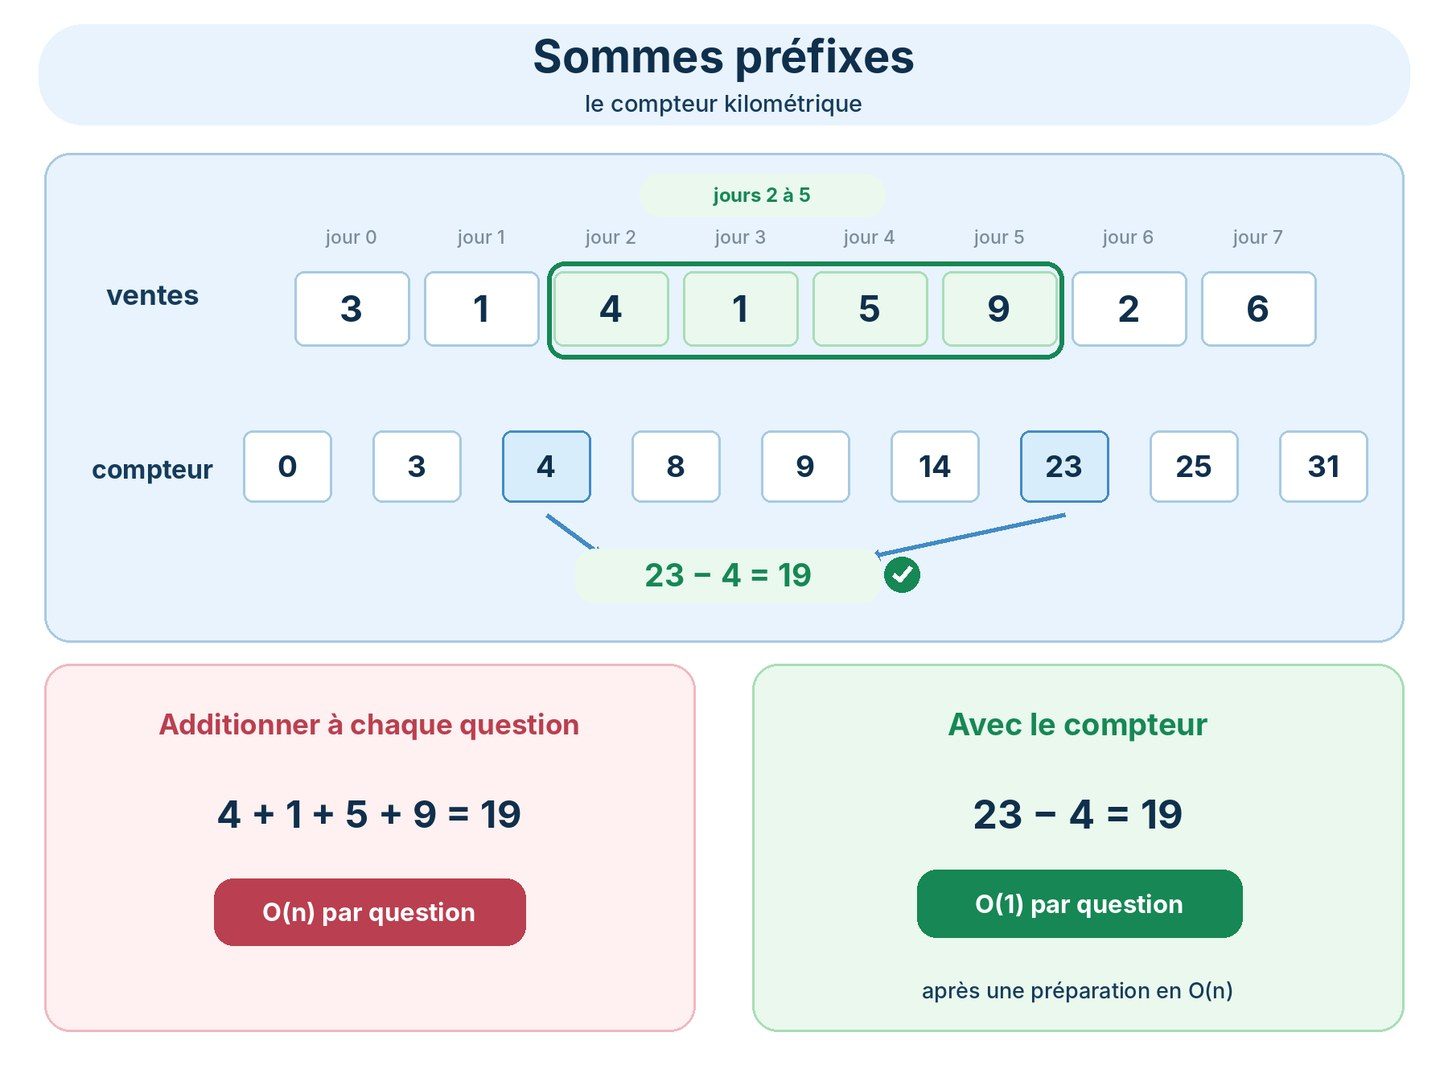

Sur l'image, la ligne du haut contient les ventes, la ligne du bas le compteur (les totaux depuis le début). Pour les jours 2 à 5, encadrés, on ne lit que deux cases du compteur : 23 (le total juste après le jour 5) moins 4 (le total juste avant le jour 2) = 19. En bas, le gain : additionner à chaque question coûte O(n) par question ; avec le compteur, on paie O(n) une seule fois, puis chaque question coûte O(1).

## On manipule

In [ ]:
ventes = [3, 1, 4, 1, 5, 9, 2, 6]

prefixe = [0]                           # la somme de zéro élément
for x in ventes:
    prefixe.append(prefixe[-1] + x)     # nouveau total = total précédent + ventes du jour
print(prefixe)                          # [0, 3, 4, 8, 9, 14, 23, 25, 31]

def somme_entre(g, d):
    return prefixe[d + 1] - prefixe[g]  # (total jusqu'au jour d inclus) − (total avant le jour g)

print(somme_entre(2, 5))   # 4 + 1 + 5 + 9 = 19
print(somme_entre(0, 7))   # toute la liste : 31
print(somme_entre(3, 3))   # un seul jour : 1
print(somme_entre(0, 0))   # le tout premier jour : 3 (c'est ici que le 0 du début sert)

**Trace à la main** de la construction de `prefixe` :

| Élément lu | Calcul | `prefixe` après |
|---|---|---|
| — | départ | `[0]` |
| 3 | 0 + 3 = 3 | `[0, 3]` |
| 1 | 3 + 1 = 4 | `[0, 3, 4]` |
| 4 | 4 + 4 = 8 | `[0, 3, 4, 8]` |
| 1 | 8 + 1 = 9 | `[0, 3, 4, 8, 9]` |
| 5 | 9 + 5 = 14 | `[0, 3, 4, 8, 9, 14]` |
| 9 | 14 + 9 = 23 | `[0, 3, 4, 8, 9, 14, 23]` |
| 2 | 23 + 2 = 25 | `[0, …, 23, 25]` |
| 6 | 25 + 6 = 31 | `[0, …, 25, 31]` |

**Pourquoi ce `0` au début ?** Sans lui, une question qui commence au jour 0 demanderait « le total avant le jour 0 », qui ne serait nulle part dans le tableau : il faudrait un cas particulier. Avec lui, la même formule marche partout.

### Le piège du décalage
Le `+ 1` de `prefixe[d + 1]` s'oublie facilement. Python ne plante pas : il renvoie juste un résultat faux.

In [ ]:
print("faux  :", prefixe[5] - prefixe[2])   # 10 : il manque le jour 5 (9 ventes)
print("juste :", prefixe[6] - prefixe[2])   # 19
print("vérif :", sum(ventes[2:6]))          # 19, en additionnant à l'ancienne

**Complexité** : la construction coûte O(n), une seule fois ; chaque question coûte ensuite O(1). Pour `q` questions : O(n + q) au lieu de O(n × q).

**Variante : compter au lieu d'additionner.** Le même compteur sait **compter** : au lieu d'ajouter l'élément, on ajoute 1 s'il vérifie une condition (pair, voyelle, au-dessus d'un seuil…) et 0 sinon. `prefixe[d + 1] − prefixe[g]` donne alors le **nombre** d'éléments qui vérifient la condition entre `g` et `d`.

### Préfixes + set : repérer une portion de somme nulle
> Existe-t-il une portion **contiguë** (thème 3) dont la somme vaut exactement 0 ?
> `[3, 4, -7, 1]` → oui : 3 + 4 − 7 = 0.

Image mentale : une **randonnée**. Chaque nombre est une montée (s'il est positif) ou une descente (s'il est négatif), et le total depuis le début est l'**altitude**. Si l'on repasse par une altitude déjà connue, c'est que tout ce qu'on a monté et descendu entre-temps s'annule.
```
nombres :        3     4    -7     1
total   :   0    3     7     0     1
            ↑                 ↑
            même total (0) : entre les deux, 3 + 4 − 7 = 0
```
On lit la liste une seule fois en retenant dans un set les totaux déjà rencontrés : c'est exactement le « déjà vu ? » du thème 1, appliqué aux totaux.

In [ ]:
def existe_portion_nulle(nombres):
    vus = {0}                  # le total « avant le début » (le 0 de prefixe)
    total = 0
    for x in nombres:
        total += x             # total depuis le début, jusqu'à x inclus
        if total in vus:       # même total qu'à un moment précédent…
            return True        # … donc les éléments entre les deux s'annulent
        vus.add(total)
    return False

for t in [[3, 4, -7, 1], [1, 2, 3], [5, -5], [0], [2, -1, 3], []]:
    print(t, "->", existe_portion_nulle(t))

Sans le `0` de départ dans `vus`, `[5, -5]` répondrait `False` : la portion qui commence **au tout début** de la liste serait ratée. C'est le même rôle que le `0` au début de `prefixe`. (Et `{0}` est bien un set, avec un élément : c'est `{}` **vide** qui crée un dict.)

Pour savoir **où** se trouve la portion, ou pour trouver la plus longue, on remplace le set par un dict « total → position où on l'a vu » (thème 1).

## Partie 2 — La recherche dichotomique

### Le problème de départ
> Une liste **triée** contient un million de nombres. Le nombre 734 512 y est-il ? Si oui, à quelle position ?

`734512 in liste` regarde les cases une par une : jusqu'à un million de comparaisons. Pourtant la liste est **triée**, et cette information n'est pas du tout utilisée.

### Le concept : le jeu du nombre mystère
« Je pense à un nombre entre 1 et 100. » Personne ne propose 1, puis 2, puis 3… On propose **50**. Réponse : « plus grand ». D'un coup, **la moitié des possibilités a disparu** : le nombre est entre 51 et 100. On propose alors 75, puis 62… En 7 questions au plus, on trouve n'importe quel nombre entre 1 et 100.

C'est la **recherche dichotomique** (en anglais *binary search*) : on garde une zone `bas … haut` où la cible peut encore se trouver, on regarde la case du **milieu**, et on élimine la moitié qui ne peut pas contenir la cible.

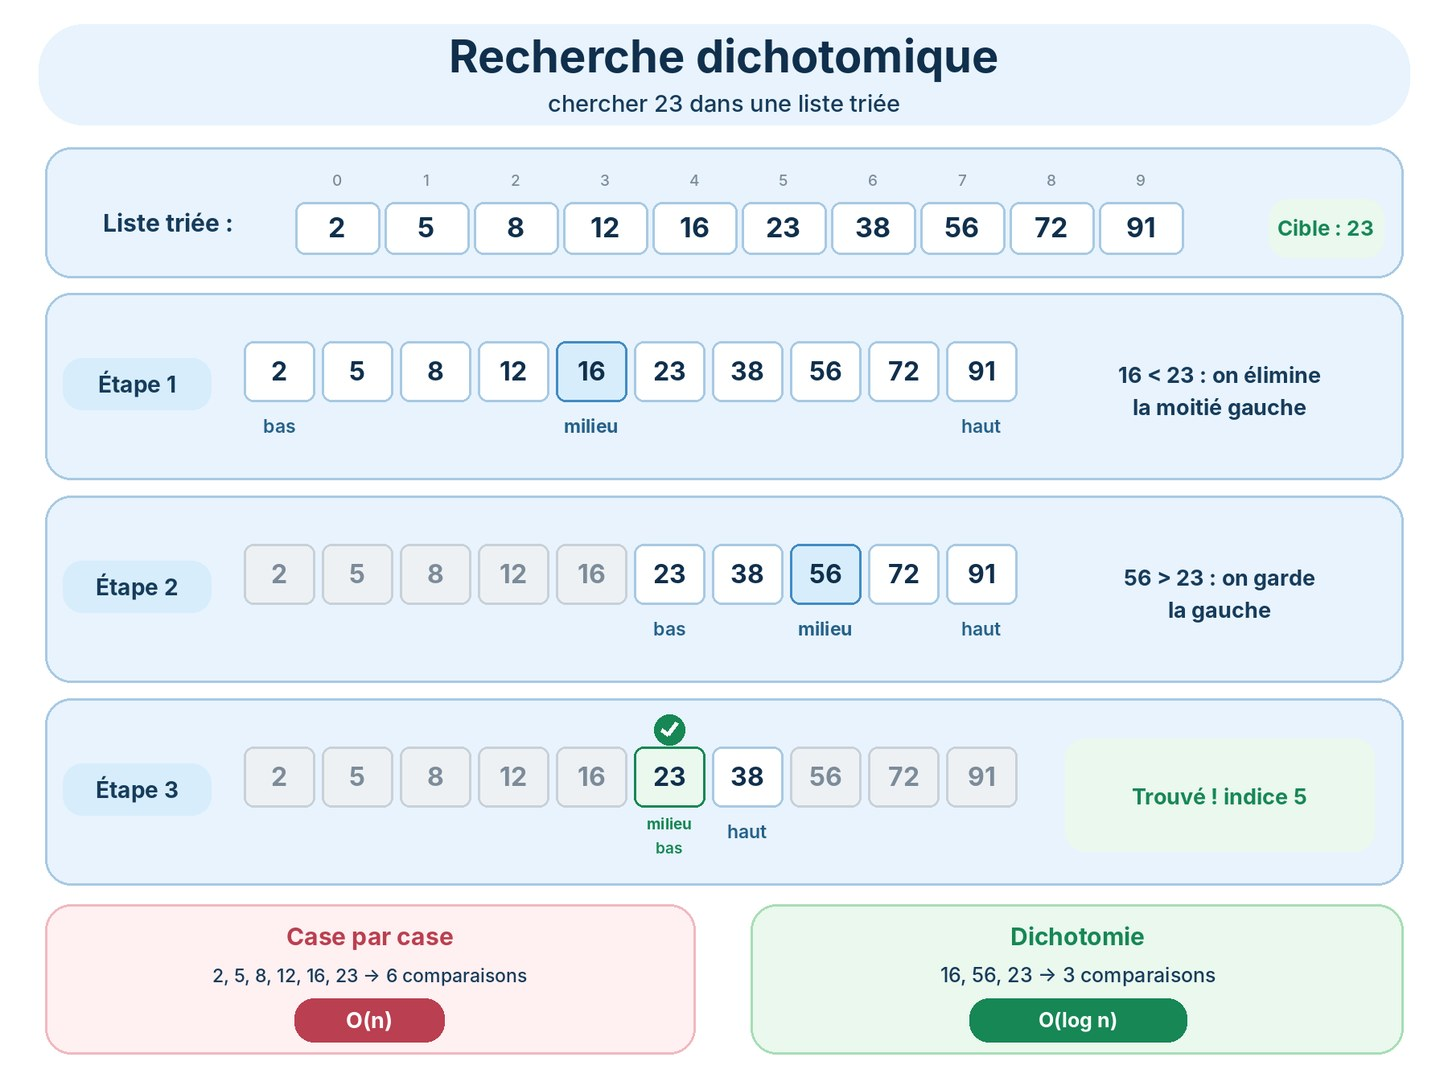

Sur l'image, on cherche 23 dans une liste triée de 10 nombres. ① La zone couvre les indices 0 à 9 ; le milieu (indice 4) vaut 16 : trop petit, donc 23 ne peut être qu'à droite, et toute la moitié gauche est éliminée (grisée). ② La zone couvre les indices 5 à 9 ; le milieu (indice 7) vaut 56 : trop grand, on garde la gauche. ③ La zone couvre les indices 5 et 6 ; le milieu (indice 5) vaut 23 : trouvé. En bas : la recherche case par case aurait fait 6 comparaisons, la dichotomie en fait 3, et l'écart explose quand la liste grandit.

**Pourquoi c'est si rapide ?** Chaque étape divise par 2 le nombre de candidats : 1 000 000 → 500 000 → 250 000 → … → 1, en une vingtaine d'étapes. C'est le log₂ n du thème 0 : **O(log n)**.

| Taille de la liste | Case par case : O(n) | Dichotomie : O(log n) |
|---|---|---|
| 1 000 | jusqu'à 1 000 comparaisons | 10 |
| 1 000 000 | jusqu'à 1 000 000 | 20 |
| 1 000 000 000 | jusqu'à 1 000 000 000 | 30 |

**Condition indispensable : la liste doit être triée.** Sinon, la valeur du milieu ne dit rien sur ce qui se trouve à sa gauche ou à sa droite.

## On manipule

In [ ]:
def recherche_dichotomique(liste_triee, cible, afficher=False):
    bas, haut = 0, len(liste_triee) - 1        # la cible ne peut être qu'entre bas et haut (inclus)
    while bas <= haut:                         # tant qu'il reste au moins un candidat
        milieu = (bas + haut) // 2
        if afficher:
            print(f"bas={bas} haut={haut} milieu={milieu} → valeur {liste_triee[milieu]}")
        if liste_triee[milieu] == cible:
            return milieu                      # trouvé
        elif liste_triee[milieu] < cible:
            bas = milieu + 1                   # le milieu et tout ce qui est à sa gauche sont trop petits
        else:
            haut = milieu - 1                  # le milieu et tout ce qui est à sa droite sont trop grands
    return -1                                  # la zone est vide : la cible n'est pas dans la liste

nombres = [2, 5, 8, 12, 16, 23, 38, 56, 72, 91]
print(recherche_dichotomique(nombres, 23, afficher=True))   # 5
print()
print(recherche_dichotomique(nombres, 40, afficher=True))   # -1

**Trace à la main** (cible = 23), comme sur l'image :

| Étape | `bas` | `haut` | `milieu` | valeur | décision |
|---|---|---|---|---|---|
| 1 | 0 | 9 | 4 | 16 | 16 < 23 → `bas = 5` |
| 2 | 5 | 9 | 7 | 56 | 56 > 23 → `haut = 6` |
| 3 | 5 | 6 | 5 | 23 | **trouvé** → on renvoie 5 |

Pour 40, qui est absent, la zone rétrécit jusqu'à devenir vide (`bas` dépasse `haut`), et la fonction renvoie -1.

### Pourquoi `milieu + 1` et `milieu - 1`, et pas `milieu` ?
La case du milieu vient d'être examinée : on peut l'**exclure**. C'est ce qui garantit que la zone rétrécit d'au moins une case à chaque tour. Avec `bas = milieu`, la zone peut cesser de rétrécir… et la boucle ne s'arrête plus jamais :

In [ ]:
def dichotomie_FAUSSE(liste_triee, cible):
    bas, haut = 0, len(liste_triee) - 1
    tours = 0
    while bas <= haut:
        tours += 1
        if tours > 20:                          # garde-fou, seulement pour la démonstration
            return f"bloquée : bas={bas} et haut={haut} ne bougent plus"
        milieu = (bas + haut) // 2
        if liste_triee[milieu] == cible:
            return milieu
        elif liste_triee[milieu] < cible:
            bas = milieu                        # ❌ il manque le + 1
        else:
            haut = milieu - 1
    return -1

print(dichotomie_FAUSSE([2, 5, 8, 12, 16, 23, 38, 56, 72, 91], 40))

Quand `bas` et `haut` valent tous les deux 6, le milieu vaut 6, la valeur 38 est trop petite, et `bas = milieu` laisse `bas` à 6 : plus rien ne change, pour toujours.

### En Python : le module `bisect`
Python fournit la dichotomie toute faite, dans le module `bisect` :
- `bisect_left(liste_triee, x)` : la position où insérer `x` en gardant la liste triée, **avant** les éventuels `x` déjà présents. C'est aussi le **nombre d'éléments strictement plus petits que `x`** ;
- `bisect_right(liste_triee, x)` : pareil, mais **après** les `x` déjà présents. C'est le **nombre d'éléments inférieurs ou égaux à `x`**.

In [ ]:
from bisect import bisect_left, bisect_right

notes = [8, 10, 10, 10, 12, 15, 15, 18]
print(bisect_left(notes, 10))     # 1 : un seul élément < 10 (le 8)
print(bisect_right(notes, 10))    # 4 : quatre éléments ≤ 10
print("10 apparaît", bisect_right(notes, 10) - bisect_left(notes, 10), "fois")   # 3
print(bisect_left(notes, 11))     # 4 : 11 est absent, il s'insérerait à la position 4

Chaque appel coûte O(log n). Compter les 10 avec `notes.count(10)` coûterait O(n) : une boucle cachée.

### Chercher la réponse elle-même : la dichotomie sur la réponse
La dichotomie ne sert pas qu'à chercher **dans une liste**. Elle cherche dans n'importe quelle suite de candidats **rangés dans l'ordre**, dès qu'on sait répondre à la question « trop petit ou trop grand ? ».

> On empile des cubes en escalier : 1 cube au 1er étage, 2 au 2e, 3 au 3e… Avec `n` étages complets, on utilise 1 + 2 + … + n = n × (n + 1) / 2 cubes. **Combien d'étages complets au maximum** peut-on construire avec `cubes` cubes ?
> 20 cubes → **5** étages (5 étages utilisent 15 cubes ; 6 étages en demanderaient 21).

Essayer 1 étage, puis 2, puis 3… fonctionne, mais si `cubes` vaut 10¹⁸, il faudrait plus d'un milliard d'essais. Or la question « `n` étages, est-ce possible ? » a une propriété précieuse : si c'est possible pour `n`, c'est possible pour tout nombre plus petit ; si c'est impossible pour `n`, c'est impossible pour tout nombre plus grand. Les réponses sont rangées **oui, oui, …, oui, non, non, …** : on cherche le dernier « oui » par dichotomie.

In [ ]:
def etages_max(cubes):
    bas, haut = 0, cubes          # la réponse est forcément entre 0 et cubes
    meilleur = 0                  # le plus grand nombre d'étages possible trouvé jusqu'ici
    while bas <= haut:
        milieu = (bas + haut) // 2
        if milieu * (milieu + 1) // 2 <= cubes:   # milieu étages : assez de cubes ?
            meilleur = milieu                     # oui : c'est un candidat… on tente plus haut
            bas = milieu + 1
        else:
            haut = milieu - 1                     # non : trop d'étages, on tente plus bas
    return meilleur

print(etages_max(20))        # 5
print(etages_max(21))        # 6 : pile assez pour 6 étages
print(etages_max(0))         # 0
print(etages_max(10**18))    # 1414213561, instantané : une soixantaine d'étapes seulement

**Trace à la main** (cubes = 20) :

| `bas` | `haut` | `milieu` | cubes nécessaires | assez ? | `meilleur` |
|---|---|---|---|---|---|
| 0 | 20 | 10 | 55 | non → `haut = 9` | 0 |
| 0 | 9 | 4 | 10 | oui → `bas = 5` | 4 |
| 5 | 9 | 7 | 28 | non → `haut = 6` | 4 |
| 5 | 6 | 5 | 15 | oui → `bas = 6` | 5 |
| 6 | 6 | 6 | 21 | non → `haut = 5` | 5 |

`bas` (6) a dépassé `haut` (5) : la zone est vide, la réponse est `meilleur`, soit 5.

Cette forme (« si `milieu` convient, on le retient dans `meilleur` et on cherche plus haut ») est la plus sûre à écrire en test : c'est la même boucle `while bas <= haut`, avec `milieu + 1` et `milieu - 1`, que pour chercher dans une liste. Pas de risque de boucle infinie.

## Partie 3 — Trier, et trier avec une clé

### Le problème de départ
> Une liste d'élèves avec leur note : `[("Lina", 15), ("Hugo", 12), ("Adam", 15), ("Zoé", 18)]`. Classe-les de la **meilleure note** à la moins bonne ; **en cas d'égalité**, par ordre alphabétique.
> → Zoé (18), Adam (15), Lina (15), Hugo (12).

### Le concept
- `sorted(liste)` renvoie une **nouvelle** liste triée, sans toucher à l'originale ; `liste.sort()` trie la liste **elle-même** (on dit « sur place ») et ne renvoie rien. Les deux coûtent O(n log n) (thème 0).
- Des **tuples** se comparent comme des mots dans le dictionnaire : d'abord le 1er élément ; en cas d'égalité, le 2e ; etc. `("Adam", 15) < ("Lina", 12)` est vrai, car "Adam" < "Lina".
- `key=` indique **selon quoi** trier : Python calcule la **clé** de chaque élément, puis trie selon ces clés. Image mentale : on colle une étiquette sur chaque copie d'examen, puis on range les copies en ne regardant **que les étiquettes**.
- `lambda e: e[1]` est une mini-fonction écrite en une ligne : « on me donne `e`, je renvoie `e[1]` ».

Pour « note décroissante, puis nom croissant », l'étiquette est le tuple `(-note, nom)` : le signe moins inverse l'ordre des notes (−18 < −15 < −12), et le nom départage les égalités.

In [ ]:
eleves = [("Lina", 15), ("Hugo", 12), ("Adam", 15), ("Zoé", 18)]

print(sorted(eleves))                                     # par nom : le 1er élément du tuple
print(sorted(eleves, key=lambda e: e[1]))                 # par note croissante
print(sorted(eleves, key=lambda e: e[1], reverse=True))   # par note décroissante (Lina reste avant Adam)
print(sorted(eleves, key=lambda e: (-e[1], e[0])))        # note ↓, puis nom ↑ en cas d'égalité

Remarque sur la 3e ligne : à note égale, Lina reste avant Adam, comme dans la liste de départ. Le tri de Python est **stable** : il ne change jamais l'ordre de deux éléments qui ont la même clé. Pour départager les égalités selon **une règle de l'énoncé**, il faut donc mettre cette règle dans la clé, comme à la 4e ligne.

Deux erreurs classiques :

In [ ]:
notes = [12, 5, 18]
resultat = notes.sort()
print(resultat)        # None ! sort() trie la liste elle-même et ne renvoie rien
print(notes)           # [5, 12, 18]

# Les majuscules passent AVANT toutes les minuscules (et les lettres accentuées après le z)
print(sorted(["banane", "Cerise", "abricot"]))                  # ['Cerise', 'abricot', 'banane']
print(sorted(["banane", "Cerise", "abricot"], key=str.lower))   # ['abricot', 'banane', 'Cerise']
# key=str.lower : l'étiquette de chaque mot est sa version en minuscules

### Trier d'abord, pour que les éléments liés deviennent voisins
Beaucoup de problèmes deviennent simples une fois la liste triée, parce que les éléments qui « vont ensemble » se retrouvent **côte à côte**. Un seul passage, en comparant chaque élément à son voisin, suffit alors.

> Des réunions `[début, fin]`, en heures. Une personne peut-elle **toutes** les suivre ? Une réunion qui commence pile à l'heure où une autre finit ne la chevauche pas.
> `[[9, 11], [13, 15], [10, 12]]` → non : 9 h–11 h et 10 h–12 h se chevauchent.

**Approche naïve** : comparer chaque réunion à toutes les autres → O(n²).

**En triant par heure de début** : s'il existe deux réunions qui se chevauchent, alors il en existe aussi deux **voisines dans la liste triée** qui se chevauchent. (Si une réunion commence avant la fin d'une réunion plus ancienne, la réunion qui suit immédiatement cette ancienne commence, elle aussi, avant cette fin.) Il suffit donc de comparer chaque réunion à celle qui la précède.

In [ ]:
def peut_tout_suivre(reunions):
    reunions = sorted(reunions)                 # par heure de début (le 1er élément)
    for k in range(1, len(reunions)):
        debut = reunions[k][0]
        fin_precedente = reunions[k - 1][1]
        if debut < fin_precedente:              # commence avant la fin de la réunion précédente
            return False
    return True

print(peut_tout_suivre([[9, 11], [13, 15], [10, 12]]))   # False
print(peut_tout_suivre([[13, 15], [9, 11], [11, 12]]))   # True : 11 h–12 h commence pile à la fin de 9 h–11 h
print(peut_tout_suivre([]))                              # True : rien à suivre

**Trace à la main** sur le premier exemple. Après le tri : `[[9, 11], [10, 12], [13, 15]]`.

| `k` | réunion | fin de la précédente | chevauchement ? |
|---|---|---|---|
| 1 | [10, 12] | 11 | 10 < 11 → **oui** → on renvoie `False` |

**Complexité** : O(n log n) pour le tri, puis O(n) pour le passage → O(n log n). Les problèmes d'**intervalles** (réunions, réservations, plages horaires) commencent presque toujours par un tri, par début ou par fin.

### Quelle technique choisir ?
| Technique | Ce qu'elle fait | Coût |
|---|---|---|
| Sommes préfixes | répondre à beaucoup de questions « somme / nombre entre `g` et `d` » | O(n) une fois, puis O(1) par question |
| Préfixes + set / dict | trouver une portion contiguë de somme donnée | O(n) |
| Dichotomie / `bisect` | chercher dans une liste **triée** | O(log n) par recherche |
| Dichotomie sur la réponse | trouver « le plus grand / le plus petit `x` tel que… » | O(log de l'intervalle des réponses possibles) |
| Tri avec `key=` | classer selon plusieurs critères, rendre voisins les éléments liés | O(n log n) |

## Quand y penser ?
- « beaucoup de requêtes », « pour chaque question `[g, d]` », « somme / nombre d'éléments entre deux positions » → **sommes préfixes** ;
- « portion contiguë de somme nulle / égale à `k` » → **préfixes + set ou dict** ;
- « liste triée » + « chercher », « combien de valeurs entre `a` et `b` » → **dichotomie / `bisect`** ;
- « le plus grand `x` tel que… », « le plus petit `x` tel que… », avec des nombres énormes (10¹², 10¹⁸) → **dichotomie sur la réponse** ;
- « classer par… puis par… », « en cas d'égalité… » → **`sorted` avec une clé** ;
- intervalles, réunions, plages horaires, « fusionner », « se chevauchent » → **trier d'abord**.

## Les pièges
- Le décalage des préfixes : `prefixe[d + 1] − prefixe[g]`, et `prefixe` a `n + 1` cases.
- Oublier le `0` de départ (dans `prefixe` ou dans le set) → les portions qui commencent au tout début sont ratées.
- Dichotomie : `bas = milieu` au lieu de `milieu + 1` → boucle infinie.
- Dichotomie sur une liste **non triée** → résultat faux, sans aucune erreur.
- `x = liste.sort()` → `x` vaut `None`.
- Dans un tri de textes, les majuscules passent avant les minuscules.
- Trier coûte O(n log n) et fait perdre les positions d'origine : si l'énoncé demande des indices, garde-les avec `enumerate` avant de trier.

## À toi de jouer — l'indice d'équilibre
> Écris `indice_equilibre(nombres)` qui renvoie le **premier** indice `i` tel que la somme des éléments **à gauche** de `i` est égale à la somme des éléments **à droite** de `i` (l'élément `i` lui-même n'est d'aucun côté). S'il n'y en a aucun, renvoie `-1`. Une somme vide vaut 0.
> `indice_equilibre([1, 7, 3, 6, 5, 6])` → `3` : à gauche 1 + 7 + 3 = 11, à droite 5 + 6 = 11.

Contrainte : jusqu'à 100 000 éléments. Recalculer les deux sommes pour chaque `i` coûterait O(n²) : trop lent.

**Indice** : calcule d'abord le `total` de la liste. Avance ensuite en tenant à jour `gauche`, la somme des éléments déjà passés (comme le compteur kilométrique). Pour l'indice `i`, la somme à droite vaut alors `total - gauche - nombres[i]`.

In [ ]:
def indice_equilibre(nombres):
    # À toi de jouer !
    pass

verifier(indice_equilibre, [
    (([1, 7, 3, 6, 5, 6],), 3),
    (([1, 2, 3],), -1),
    (([2, 1, -1],), 0),        # à gauche : rien (0) ; à droite : 1 + (-1) = 0
    (([1, -1, 4],), 2),        # l'équilibre peut être au dernier indice
    (([5],), 0),               # les deux côtés sont vides
    (([],), -1),
])

<details>
<summary><b>Voir la solution</b> (essaie vraiment d'abord !)</summary>

```python
def indice_equilibre(nombres):
    total = sum(nombres)
    gauche = 0                              # somme des éléments situés avant l'indice i
    for i, x in enumerate(nombres):
        droite = total - gauche - x         # tout le reste, sauf l'élément i lui-même
        if gauche == droite:
            return i
        gauche += x                         # x passe du côté gauche pour l'indice suivant
    return -1

# Un passage pour le total, un passage pour chercher : O(n).
```

</details>

---

**Suite :** [Thème 7 — Mathématiques et algorithmes gloutons](theme7_maths_gloutons.ipynb) ➡ · [Retour au sommaire](00_sommaire.ipynb)

**S'entraîner :** [Série 6 — Sommes préfixes, recherche et tri](exercices/serie6_prefixes_recherche_tri.ipynb) (6 exercices avec tests automatiques)